# 01 — Data exploration: Cochrane paragraph simplification

**Dataset:** Devaraj et al., *Paragraph-level Simplification of Medical Texts*, NAACL 2021 (CC BY 4.0).
Each example pairs the technical part of a Cochrane review abstract (**source**) with the review's plain-language summary written for the public (**target**).

**Questions this notebook answers**
1. How many pairs are there per split, and what do they look like?
2. How long are sources and targets in **FLAN-T5 tokens**? This decides the maximum input/output lengths for training.
3. How much harder to read are sources than targets (Flesch-Kincaid Grade Level)? This is the readability gap the model must learn to close.
4. Does the T5 tokenizer lose characters that matter in medical text (unknown tokens)?

Prerequisite: `python -m src.data.download` has created `data/processed/*.jsonl`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import textstat
from transformers import AutoTokenizer

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed"
FIGURES = ROOT / "docs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT))
from src.eval.readability import fkgl  # decimal-safe FKGL (see section 3)

def load(split):
    with (DATA / f"{split}.jsonl").open(encoding="utf-8") as f:
        return pd.DataFrame([json.loads(line) for line in f]).assign(split=split)

df = pd.concat([load(s) for s in ("train", "val", "test")], ignore_index=True)
df.groupby("split", sort=False).size().rename("pairs").to_frame()

,pairs
split,
train,3567
val,411
test,480


## 1. One example pair

In [2]:
ex = df[df.split == "train"].iloc[0]
print("ID:", ex.id, "\n")
print("SOURCE (technical):\n", ex.source, "\n")
print("TARGET (plain language):\n", ex.target)

ID: 10.1002/14651858.CD001836.pub4 

SOURCE (technical):
 Two trials met the inclusion criteria. One compared 2% ketanserin ointment in polyethylene glycol (PEG) with PEG alone, used twice a day by 40 participants with arterial leg ulcers, for eight weeks or until healing, whichever was sooner. One compared topical application of blood-derived concentrated growth factor (CGF) with standard dressing (polyurethane film or foam); both applied weekly for six weeks by 61 participants with non-healing ulcers (venous, diabetic arterial, neuropathic, traumatic, or vasculitic). Both trials were small, reported results inadequately, and were of low methodological quality. Short follow-up times (six and eight weeks) meant it would be difficult to capture sufficient healing events to allow us to make comparisons between treatments. One trial demonstrated accelerated wound healing in the ketanserin group compared with the control group. In the trial that compared CGF with standard dressings, the nu

## 2. Length in FLAN-T5 tokens

The model never sees words, it sees **tokens** (sub-word pieces from the SentencePiece vocabulary of `google/flan-t5-base`). Training needs a fixed maximum length; anything longer is cut off (truncated). We measure how many examples would be truncated at each candidate length.

In [3]:
tok = AutoTokenizer.from_pretrained("google/flan-t5-base")
PREFIX = "simplify: "  # the task prefix we will prepend at training time

df["src_tokens"] = [len(ids) for ids in tok([PREFIX + s for s in df.source])["input_ids"]]
df["tgt_tokens"] = [len(ids) for ids in tok(list(df.target))["input_ids"]]
df["src_words"] = df.source.str.split().str.len()
df["tgt_words"] = df.target.str.split().str.len()

df[["src_tokens", "tgt_tokens", "src_words", "tgt_words"]].describe(
    percentiles=[0.5, 0.9, 0.95, 0.99]).round(0)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (587 > 512). Running this sequence through the model will result in indexing errors


,src_tokens,tgt_tokens,src_words,tgt_words
count,4458.0,4458.0,4458.0,4458.0
mean,538.0,287.0,350.0,212.0
std,225.0,149.0,143.0,108.0
min,168.0,43.0,129.0,27.0
50%,491.0,265.0,320.0,198.0
90%,882.0,486.0,559.0,355.0
95%,970.0,580.0,620.0,425.0
99%,1064.0,738.0,701.0,530.0
max,1165.0,1000.0,772.0,690.0


In [4]:
rows = []
for limit in (256, 384, 512, 768, 1024):
    rows.append({
        "max length": limit,
        "sources truncated (%)": round(100 * (df.src_tokens > limit).mean(), 1),
        "targets truncated (%)": round(100 * (df.tgt_tokens > limit).mean(), 1),
    })
truncation = pd.DataFrame(rows).set_index("max length")
truncation

,sources truncated (%),targets truncated (%)
max length,,
256,94.2,52.2
384,67.9,21.9
512,47.2,8.2
768,18.2,0.7
1024,2.5,0.0


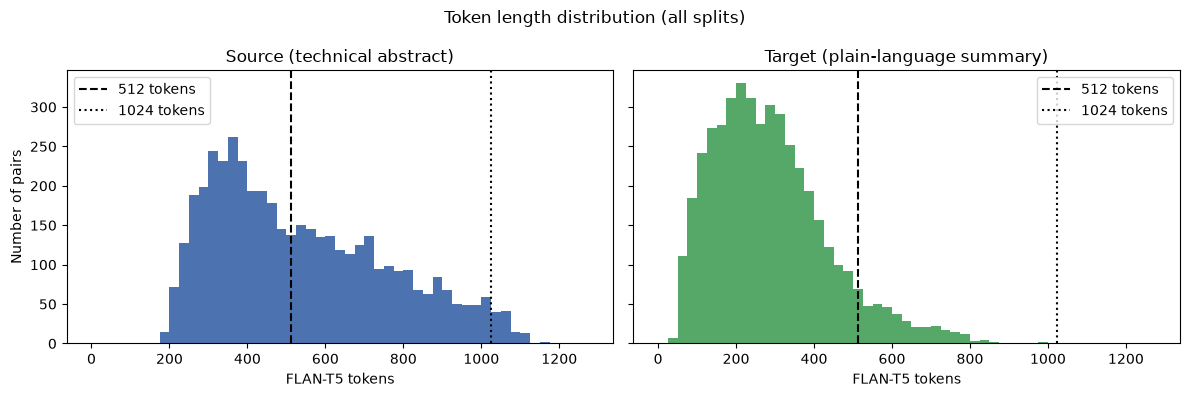

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
bins = np.arange(0, 1300, 25)
for ax, col, title in [(axes[0], "src_tokens", "Source (technical abstract)"),
                       (axes[1], "tgt_tokens", "Target (plain-language summary)")]:
    ax.hist(df[col], bins=bins, color="#4C72B0" if col == "src_tokens" else "#55A868")
    for limit, style in [(512, "--"), (1024, ":")]:
        ax.axvline(limit, color="black", linestyle=style, label=f"{limit} tokens")
    ax.set_title(title)
    ax.set_xlabel("FLAN-T5 tokens")
    ax.legend()
axes[0].set_ylabel("Number of pairs")
fig.suptitle("Token length distribution (all splits)")
fig.tight_layout()
fig.savefig(FIGURES / "token_lengths.png", dpi=150)
plt.show()

## 3. Readability gap (Flesch-Kincaid Grade Level)

FKGL estimates the US school grade needed to understand a text, from average sentence length and syllables per word. Lower = easier. Health-literacy guidelines usually aim for grade 6–8 for patient material.

**Pitfall found here:** `textstat` treats every `.` as a sentence end. Medical abstracts are full of decimals (*RR 0.85, 95% CI 0.71 to 1.02*) and abbreviations (*e.g.*, *vs.*, *et al.*), so they get chopped into many fake short sentences and look easier than they are. The first cell below shows the effect; we then use the corrected `fkgl()` from `src/eval/readability.py`, which hides those dots before scoring.

In [6]:
raw = pd.DataFrame({
    "split": df.split,
    "src_raw": df.source.map(textstat.flesch_kincaid_grade),
    "tgt_raw": df.target.map(textstat.flesch_kincaid_grade),
    "src_fixed": df.source.map(fkgl),
    "tgt_fixed": df.target.map(fkgl),
})
comparison = raw.drop(columns="split").mean().round(2).to_frame("mean FKGL (all splits)")
comparison

,mean FKGL (all splits)
src_raw,11.36
tgt_raw,13.63
src_fixed,15.29
tgt_fixed,13.83


In [7]:
df["src_fkgl"] = raw.src_fixed
df["tgt_fkgl"] = raw.tgt_fixed

fkgl_table = df.groupby("split", sort=False)[["src_fkgl", "tgt_fkgl"]].mean().round(2)
fkgl_table.loc["all"] = df[["src_fkgl", "tgt_fkgl"]].mean().round(2)
fkgl_table["gap"] = (fkgl_table.src_fkgl - fkgl_table.tgt_fkgl).round(2)
fkgl_table

,src_fkgl,tgt_fkgl,gap
split,,,
train,15.30,13.84,1.46
val,15.39,13.96,1.43
test,15.15,13.63,1.52
all,15.29,13.83,1.46


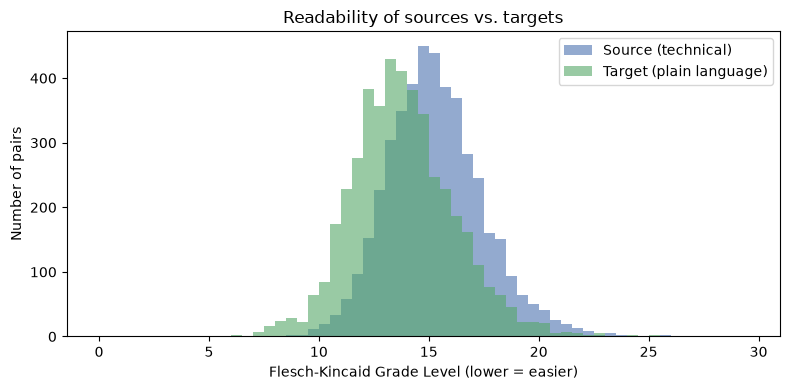

Targets easier than their source: 73.4% of pairs


In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(0, 30, 0.5)
ax.hist(df.src_fkgl, bins=bins, alpha=0.6, label="Source (technical)", color="#4C72B0")
ax.hist(df.tgt_fkgl, bins=bins, alpha=0.6, label="Target (plain language)", color="#55A868")
ax.set_xlabel("Flesch-Kincaid Grade Level (lower = easier)")
ax.set_ylabel("Number of pairs")
ax.set_title("Readability of sources vs. targets")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "fkgl_source_vs_target.png", dpi=150)
plt.show()

print(f"Targets easier than their source: {100 * (df.tgt_fkgl < df.src_fkgl).mean():.1f}% of pairs")

## 4. Unknown tokens

The T5 vocabulary has no entry for some characters (for example `<`, `{`, `~` and some accented letters). They become a single `<unk>` token and cannot be reproduced in the output. Signs like `<` matter in medical results (e.g. *P < 0.05*), so we check how often this happens.

In [9]:
unk = tok.unk_token_id
src_ids = tok(list(df.source))["input_ids"]
tgt_ids = tok(list(df.target))["input_ids"]
df["src_unk"] = [ids.count(unk) for ids in src_ids]
df["tgt_unk"] = [ids.count(unk) for ids in tgt_ids]
print(f"Sources with >=1 <unk>: {100 * (df.src_unk > 0).mean():.1f}%  (total {df.src_unk.sum()} <unk> tokens)")
print(f"Targets with >=1 <unk>: {100 * (df.tgt_unk > 0).mean():.1f}%  (total {df.tgt_unk.sum()} <unk> tokens)")

# Which characters cause them? Tokenize each distinct character on its own.
chars = sorted(set("".join(df.source) + "".join(df.target)))
unk_chars = [c for c in chars if unk in tok(c, add_special_tokens=False)["input_ids"]]
all_text = "".join(df.source) + "".join(df.target)
counts = {c: all_text.count(c) for c in unk_chars}
pd.Series(counts, name="occurrences").sort_values(ascending=False).head(15).to_frame()

Sources with >=1 <unk>: 16.7%  (total 2208 <unk> tokens)
Targets with >=1 <unk>: 2.1%  (total 179 <unk> tokens)


,occurrences
−,826
<,751
µ,157
±,112
α,108
≥,97
μ,96
β,63
≤,32
·,27


## 5. Summary and decisions

The numbers below are filled in from the outputs above (see also `docs/PROGRESS.md`, Phase 2).

In [10]:
summary = {
    "pairs (train/val/test)": f"{(df.split=='train').sum()} / {(df.split=='val').sum()} / {(df.split=='test').sum()}",
    "median source tokens": int(df.src_tokens.median()),
    "95th pct source tokens": int(df.src_tokens.quantile(0.95)),
    "max source tokens": int(df.src_tokens.max()),
    "median target tokens": int(df.tgt_tokens.median()),
    "95th pct target tokens": int(df.tgt_tokens.quantile(0.95)),
    "max target tokens": int(df.tgt_tokens.max()),
    "sources truncated at 512 (%)": truncation.loc[512, "sources truncated (%)"],
    "sources truncated at 1024 (%)": truncation.loc[1024, "sources truncated (%)"],
    "targets truncated at 512 (%)": truncation.loc[512, "targets truncated (%)"],
    "mean FKGL source (decimal-safe)": fkgl_table.loc["all", "src_fkgl"],
    "mean FKGL target (decimal-safe)": fkgl_table.loc["all", "tgt_fkgl"],
    "targets easier than source (%)": round(100 * (df.tgt_fkgl < df.src_fkgl).mean(), 1),
    "sources with >=1 <unk> token (%)": round(100 * (df.src_unk > 0).mean(), 1),
}
pd.Series(summary, name="value").to_frame()

,value
pairs (train/val/test),3567 / 411 / 480
median source tokens,491
95th pct source tokens,970
max source tokens,1165
median target tokens,265
95th pct target tokens,580
max target tokens,1000
sources truncated at 512 (%),47.2
sources truncated at 1024 (%),2.5
targets truncated at 512 (%),8.2
